# Quantifying Attributions Across Multiple Experimental Configurations
Reviewers have repeatedly addressed the qualitative method of evaluating attribution maps.
In this notebook, we:
- Load attribution results across 3 experimental configurations (`frozen`, `from_scratch`, `finetuned`) totaling
  **15 independent runs** (5 runs per config) using `ExperimentResults` and `AttributionAnalyzer`
- Compute per-run spatial aggregate relevance vectors $M^{(r)} \in \mathbb{R}^{64}$ across all 15 runs
- Test for each electrode whether its relevance is higher than the background with a one-sided **Mann–Whitney U test**,
  **Benjamini–Hochberg FDR-corrected**, reported in APA style (section 2)
- Visualize spatial attribution topomaps and the FDR-significant electrodes (section 3)
- Correlate electrode relevance with test balanced accuracy (**Spearman**, section 4) and write booktabs tables and a
  statistics cache to `results/apa_mwu/` (section 4b)
- Correlate electrode relevance with training metrics (section 5)

**Data.** The run folders are read from `out/physionet_binary_frozen_evaluation`,
`out/true_binary_physionet_from_scratch_evaluation` and `out/true_binary_physionet_pretrained_evaluation`, restored
from the MPCDF tape archive (`/r/j/$USER/foundational_xai_neuroimaging_archive/physionet_evaluations.tar.zstd`).

In [1]:
%load_ext autoreload
%autoreload 2
import sys, os
sys.path.append(os.path.abspath(os.path.join('..', '..', 'src')))

import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, false_discovery_control, ranksums

from evaluate.analysis_utils import ExperimentResults, AttributionAnalyzer
from evaluate.analyze import plot_summary_grid
from visualization.eeg_attribution import plot_attribution_summary, attribution_topomap

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

## Statistical test and reporting helpers

All group comparisons in this notebook use the **Mann–Whitney U test** (`scipy.stats.mannwhitneyu`) with
**normal approximation, tie correction and no continuity correction**.
Without ties this yields exactly the z and p of `scipy.stats.ranksums`, which earlier versions of the analysis used.

Every test reports, in APA style:
* each group characterized by *n*, median (Mdn) and interquartile range (IQR = Q1–Q3),
* *U* (statistic of the first-named group: number of pairs in which its value is larger, ties counting ½),
* *z* (tie-corrected; *z* > 0 means the first-named group tends to be larger),
* *p* (and the FDR-adjusted *p* where several tests are run),
* the effect size *r* = *z* / √*N*, and *A* = *U* / (*n*₁*n*₂), the probability that a random value of the first group exceeds one of the second.

The cell also defines the booktabs (LaTeX) table builder and `write_output`, which saves the `.tex` tables and a
`.json` statistics cache (inputs, results, code and library versions, data locations) to `results/apa_mwu/`.
This cell is identical in the four notebooks that report these statistics (listed at the top of the cell).

In [2]:
# ---- Mann–Whitney U test with APA reporting, booktabs tables and a statistics cache ----
# This cell is identical in quantifying_attr_on_arousal.ipynb, quantifying_attr_on_physiomi.ipynb,
# clever_hans_lateral_holdout_mwu.ipynb and electrode_statistics_summary.ipynb.
import datetime
import json
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.stats import mannwhitneyu, norm

# Repository root (folder holding pyproject.toml), independent of where the kernel was started.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
STATS_DIR = PROJECT_ROOT / "results" / "apa_mwu"  # .tex tables and .json statistics caches are written here

# Normal approximation with tie correction, without continuity correction.
# Without ties this gives exactly the z and p of scipy.stats.ranksums (checked below where ranksums was used before).
MWU_SETTINGS = {"method": "asymptotic", "use_continuity": False}
MWU_SETTINGS_TEXT = "normal approximation with tie correction, no continuity correction"


def mwu_apa(x, y, alternative, label_x, label_y):
    """Mann–Whitney U test of x vs. y, returning every quantity needed for APA reporting.

    U    statistic of x: number of pairs (x_i, y_j) with x_i > y_j, ties counting 1/2 (scipy's convention).
    z    (U - n_x n_y / 2) / sigma_U with the tie-corrected sigma_U; z > 0 means x tends to be larger than y.
    p    from z under the given alternative ("greater": x tends to be larger than y).
    r    effect size z / sqrt(n_x + n_y).
    A    U / (n_x n_y), the probability that a random x exceeds a random y (common-language effect size).
    Mdn, Q1, Q3 describe each group (IQR = Q1–Q3, linear interpolation).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n_x, n_y = len(x), len(y)
    n = n_x + n_y
    res = mannwhitneyu(x, y, alternative=alternative, **MWU_SETTINGS)
    u = float(res.statistic)
    _, tie_sizes = np.unique(np.concatenate([x, y]), return_counts=True)
    sigma_u = np.sqrt(n_x * n_y / 12 * ((n + 1) - np.sum(tie_sizes**3 - tie_sizes) / (n * (n - 1))))
    z = (u - n_x * n_y / 2) / sigma_u
    # scipy does not return z; the p-value recomputed from our z must equal scipy's p-value
    p_from_z = {"greater": norm.sf(z), "less": norm.cdf(z), "two-sided": 2 * norm.sf(abs(z))}[alternative]
    assert np.isclose(p_from_z, res.pvalue, rtol=1e-9, atol=0), (p_from_z, res.pvalue)
    (q1_x, mdn_x, q3_x), (q1_y, mdn_y, q3_y) = np.percentile(x, [25, 50, 75]), np.percentile(y, [25, 50, 75])
    return {
        "label_x": label_x, "label_y": label_y, "alternative": alternative,
        "n_x": n_x, "mdn_x": mdn_x, "q1_x": q1_x, "q3_x": q3_x,
        "n_y": n_y, "mdn_y": mdn_y, "q1_y": q1_y, "q3_y": q3_y,
        "U": u, "z": z, "p": float(res.pvalue), "r": z / np.sqrt(n), "A": u / (n_x * n_y),
        "n_tied_values": int(np.sum(tie_sizes[tie_sizes > 1])),  # observations sharing their value with another one
    }


# ---- APA number formatting ----
def fmt_bounded(v, digits=2):
    """Quantities that cannot exceed 1 in absolute value (p, r, rho): no leading zero."""
    return f"{v:.{digits}f}".replace("0.", ".", 1)


def fmt_p(p):
    """'< .001', '> .999' or '= .023'."""
    if p < 0.001:
        return "< .001"
    if p > 0.999:
        return "> .999"
    return "= " + fmt_bounded(p, 3)


def fmt_u(u):
    return f"{u:.1f}".removesuffix(".0")  # U is an integer or ends in .5 (ties)


def describe_group(s, which, digits=3):
    """Characterization of one group, e.g. 'relevance at AF7 (n = 15, Mdn = .041, IQR = .027–.052)'.

    All compared quantities here (relative relevance, balanced accuracy) cannot exceed 1: no leading zero (APA).
    """
    f = lambda v: fmt_bounded(v, digits)
    return (f"{s['label_' + which]} (n = {s['n_' + which]}, Mdn = {f(s['mdn_' + which])}, "
            f"IQR = {f(s['q1_' + which])}–{f(s['q3_' + which])})")


def apa_mwu_text(s, p_adj=None):
    """'U = 11204, z = 4.12, p < .001, r = .14' (with 'p_FDR ...' if an adjusted p-value is given)."""
    text = f"U = {fmt_u(s['U'])}, z = {s['z']:.2f}, p {fmt_p(s['p'])}"
    if p_adj is not None:
        text += f", p_FDR {fmt_p(p_adj)}"
    return text + f", r = {fmt_bounded(s['r'])}"


def apa_mwu_sentence(s, alpha=0.05, p_adj=None, digits=3, describe_y=True):
    """Full sentence: both groups characterized, the direction, and the test statistics.

    Significance is decided on p_adj if given, otherwise on p.
    describe_y=False names the second group without n, Mdn and IQR, for a group that is characterized once
    for many tests (see describe_background).
    """
    significant = (p_adj if p_adj is not None else s["p"]) < alpha
    if s["alternative"] == "greater":
        verdict = "was significantly higher than" if significant else "was not significantly higher than"
    elif s["alternative"] == "less":
        verdict = "was significantly lower than" if significant else "was not significantly lower than"
    elif significant:
        verdict = "was significantly higher than" if s["z"] > 0 else "was significantly lower than"
    else:
        verdict = "did not differ significantly from"
    first = describe_group(s, "x", digits)
    second = describe_group(s, "y", digits) if describe_y else s["label_y"]
    return f"{first[0].upper()}{first[1:]} {verdict} {second}, {apa_mwu_text(s, p_adj)}."


def fmt_range(values, digits=3, dash="–"):
    """'.014' if all values round to the same number, else 'min–max', e.g. '.024–.025'."""
    lo, hi = fmt_bounded(min(values), digits), fmt_bounded(max(values), digits)
    return lo if lo == hi else f"{lo}{dash}{hi}"


def describe_background(results, digits=3, tex=False):
    """One phrase characterizing the background group of all electrode-vs-background tests at once.

    The background of electrode c is all other electrodes, so it hardly changes from test to test. Its n, Mdn, Q1 and
    Q3 are given as ranges over the tests (one value where all tests round to the same number); "virtually identical"
    is only stated if every range spans at most one unit of the last digit shown. The per-test values stay in the
    results (n_y, mdn_y, q1_y, q3_y).
    """
    dash = "--" if tex else "–"
    stats = ", ".join(f"{name} = {fmt_range(results[col], digits, dash)}" for name, col in [("Mdn", "mdn_y"), ("Q1", "q1_y"), ("Q3", "q3_y")])
    n_y = sorted(set(results["n_y"]))
    n_text = str(n_y[0]) if len(n_y) == 1 else f"{n_y[0]}{dash}{n_y[-1]}"
    n_text = f"$n = {n_text}$" if tex else f"n = {n_text}"
    identical = all(results[col].max() - results[col].min() <= 10 ** -digits for col in ["mdn_y", "q1_y", "q3_y"])
    verdict = "was virtually identical in all" if identical else "varied across the"
    return (f"The background group, the relative relevance of all other electrodes in all runs ({n_text} per test), "
            f"{verdict} {len(results)} tests ({stats} across tests).")


# ---- LaTeX (booktabs) output; needs \usepackage{booktabs} (and \usepackage{longtable} for long=True) ----
def tex_p(p):
    return "$< .001$" if p < 0.001 else ("$> .999$" if p > 0.999 else f"${fmt_bounded(p, 3)}$")


def tex_num(v, digits=2, bounded=False):
    return f"${fmt_bounded(v, digits) if bounded else f'{v:.{digits}f}'}$"  # math mode gives a proper minus sign


def booktabs(header, rows, colspec, caption, label, long=False):
    """booktabs table in \\small with narrower column spacing.

    header: list of cells (one header row), or list of rows, where a row is a list of cells or a raw line (e.g. a \\cmidrule).
    long=False: floating table. long=True: longtable that breaks across pages (header repeated), for full electrode lists.
    An empty table gets one row saying so.
    """
    n_cols = sum(ch in "lcr" for ch in colspec)
    rows_of_header = header if isinstance(header[0], list) else [header]
    head = "\n".join(r if isinstance(r, str) else " & ".join(r) + r" \\" for r in rows_of_header)
    body = [" & ".join(row) + r" \\" for row in rows] or [rf"\multicolumn{{{n_cols}}}{{l}}{{No electrode with $p_{{\mathrm{{FDR}}}} < .05$}} \\"]
    if long:
        return "\n".join([
            r"{\small\setlength{\tabcolsep}{4pt}",
            rf"\begin{{longtable}}{{{colspec}}}",
            rf"\caption{{{caption}}}\label{{{label}}} \\",
            r"\toprule", head, r"\midrule", r"\endfirsthead",
            rf"\multicolumn{{{n_cols}}}{{l}}{{\emph{{(continued)}}}} \\",
            r"\toprule", head, r"\midrule", r"\endhead",
            r"\bottomrule", r"\endfoot",
            *body,
            r"\end{longtable}",
            r"}",
        ])
    return "\n".join([
        r"\begin{table}[ht]",
        r"\centering",
        r"\small",
        r"\setlength{\tabcolsep}{4pt}",
        rf"\caption{{{caption}}}",
        rf"\label{{{label}}}",
        rf"\begin{{tabular}}{{{colspec}}}",
        r"\toprule",
        head,
        r"\midrule",
        *body,
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{table}",
    ])


# ---- Output files ----
def _git(*args):
    return subprocess.run(["git", *args], cwd=PROJECT_ROOT, capture_output=True, text=True).stdout.strip()


def provenance(data_sources):
    """Everything needed to trace the numbers back: code version, library versions, data locations, test settings."""
    return {
        "created": datetime.datetime.now().isoformat(timespec="seconds"),
        "git_commit": _git("rev-parse", "HEAD"),
        "git_branch": _git("rev-parse", "--abbrev-ref", "HEAD"),
        "git_uncommitted_changes": bool(_git("status", "--porcelain")),
        "python": platform.python_version(),
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "pandas": pd.__version__,
        "mwu_settings": {**MWU_SETTINGS, "tie_correction": True, "description": MWU_SETTINGS_TEXT},
        "data_sources": data_sources,
    }


def _jsonable(o):
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (pd.DataFrame, pd.Series)):
        return json.loads(o.to_json(orient="records" if isinstance(o, pd.DataFrame) else "index"))
    if isinstance(o, Path):
        return str(o)
    raise TypeError(type(o))


def write_output(filename, content):
    """Write a .tex table (str) or a .json statistics cache (dict) to STATS_DIR and print the path."""
    STATS_DIR.mkdir(parents=True, exist_ok=True)
    path = STATS_DIR / filename
    if isinstance(content, str):
        path.write_text(content + "\n")
    else:
        path.write_text(json.dumps(content, indent=1, default=_jsonable, ensure_ascii=False) + "\n")
    print(f"written: {path}")

## 1. Load Multi-Experiment & Multi-Run Results
We load results from 3 experiment configurations: `frozen`, `from_scratch`, and `finetuned` (15 independent runs total).

In [3]:
EXPERIMENT_MAP = {
    'frozen': os.path.abspath(os.path.join('..', '..', 'out', 'physionet_binary_frozen_evaluation')),
    'from_scratch': os.path.abspath(os.path.join('..', '..', 'out', 'true_binary_physionet_from_scratch_evaluation')),
    'finetuned': os.path.abspath(os.path.join('..', '..', 'out', 'true_binary_physionet_pretrained_evaluation')),
}

experiment_data = {}
all_runs_spatial = []
run_info = []

class_names = {0: "Left Hand", 1: "Right Hand"}
physio_ch_names = ['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']

for label, path in EXPERIMENT_MAP.items():
    results = ExperimentResults(path)
    analyzer = AttributionAnalyzer(results)
    agg_stats = analyzer.calculate_aggregate_statistics(split='test', class_names=class_names)
    per_run = agg_stats['per_run_classwise']
    
    experiment_data[label] = {
        'results': results,
        'analyzer': analyzer,
        'agg_stats': agg_stats
    }
    
    print(f"Loaded {label}: {len(results.run_dirs)} runs discovered.")
    
    for r in sorted(per_run.keys()):
        m0 = per_run[r][0]['all_mean'].mean(axis=1) # (64,)
        m1 = per_run[r][1]['all_mean'].mean(axis=1) # (64,)
        cnt0 = per_run[r][0]['all_count']
        cnt1 = per_run[r][1]['all_count']
        m_pooled = (m0 * cnt0 + m1 * cnt1) / (cnt0 + cnt1)


        all_runs_spatial.append(m_pooled)

        run_info.append({'config': label, 'run': r})

mat_15runs = np.stack(all_runs_spatial) # Shape: (15, 64)´
# Work in absolute values, we observed some occ. sign flips
mat_15runs_ab = np.abs(mat_15runs)
# Normalize spatial relevance per run (L1-normalized relative relevance)
mat_15runs_norm = mat_15runs_ab / np.sum(mat_15runs_ab, axis=1, keepdims=True)
print(f"Total per-run spatial aggregate matrix shape: {mat_15runs.shape}")

Loaded frozen: 5 runs discovered.


Loaded from_scratch: 5 runs discovered.


Loaded finetuned: 5 runs discovered.
Total per-run spatial aggregate matrix shape: (15, 64)


## 2. Electrodes with higher relevance than the background: Mann–Whitney U tests

For each electrode *c*, a **one-sided Mann–Whitney U test** (H₁: values tend to be larger) compares
* group 1: the relative relevance of electrode *c*, one value per run (*n* = number of runs), with
* group 2: the relative relevance of all other electrodes of all runs ("background", *n* = runs × (electrodes − 1)).

Relative relevance: per run, the absolute spatial relevance of each electrode divided by the sum over all electrodes
($\tilde{M}_{r,c} = |M_{r,c}| / \sum_k |M_{r,k}|$), which removes scale differences between runs and configurations.
The p-values are **Benjamini–Hochberg FDR-corrected** across all electrodes; an electrode counts as relevant if $p_\mathrm{FDR} < .05$.

**Output:** one APA sentence per FDR-significant electrode and a table of the 15 electrodes with the smallest p.
Because the background of each electrode is all *other* electrodes, it is nearly the same in every test. It is therefore
characterized once, in an opening sentence (`background_description`, with Mdn, Q1 and Q3 as ranges over the tests),
and the per-electrode sentences (`sentence_short`) only name it. `sentence` holds the full sentence with both groups
characterized, and the per-test background values are kept in the results (`n_y`, `mdn_y`, `q1_y`, `q3_y`).
`sig_fdr` marks FDR significance.

*Note:* the background values of one run come from the same model as that run's electrode value; the test treats all values as independent.

In [4]:
alpha = 0.05
mwu_rows = []
for c, ch in enumerate(physio_ch_names):
    vals = mat_15runs_norm[:, c]  # relative relevance of this electrode, one value per run
    other = np.delete(mat_15runs_norm, c, 1).ravel()  # all other electrodes of all runs ("background")
    s = mwu_apa(vals, other, "greater", label_x=f"relevance at {ch}", label_y="background relevance")
    mwu_rows.append({"channel_idx": c, "channel_name": ch,
                     "mean_abs_relevance": np.mean(vals), "std_abs_relevance": np.std(vals, ddof=1), **s})

sig_15_df = pd.DataFrame(mwu_rows)
sig_15_df["p_adj"] = false_discovery_control(sig_15_df["p"].values)  # Benjamini–Hochberg across all electrodes
sig_15_df["sig_raw"] = sig_15_df["p"] < alpha
sig_15_df["sig_fdr"] = sig_15_df["p_adj"] < alpha
sig_15_df["sentence"] = [apa_mwu_sentence(s, alpha=alpha, p_adj=s["p_adj"]) for s in sig_15_df.to_dict("records")]
sig_15_df["sentence_short"] = [apa_mwu_sentence(s, alpha=alpha, p_adj=s["p_adj"], describe_y=False) for s in sig_15_df.to_dict("records")]
background_description = describe_background(sig_15_df)

print(f"Runs: {mat_15runs_norm.shape[0]}, electrodes tested: {len(sig_15_df)}")
print(f"Electrodes with raw p < {alpha}: {sig_15_df['sig_raw'].sum()} / {len(sig_15_df)}")
print(f"Electrodes with FDR p_adj < {alpha}: {sig_15_df['sig_fdr'].sum()} / {len(sig_15_df)}\n")
print("FDR-significant electrodes (APA):")
print("  " + background_description)
for sentence in sig_15_df.loc[sig_15_df["sig_fdr"]].sort_values("p")["sentence_short"]:
    print("  " + sentence)

display(sig_15_df.sort_values("p")[["channel_name", "mdn_x", "q1_x", "q3_x", "mdn_y", "U", "z", "p", "p_adj", "r", "A",
                                 "n_tied_values", "sig_fdr"]].head(15))

Runs: 15, electrodes tested: 64
Electrodes with raw p < 0.05: 14 / 64
Electrodes with FDR p_adj < 0.05: 11 / 64

FDR-significant electrodes (APA):
  The background group, the relative relevance of all other electrodes in all runs (n = 945 per test), was virtually identical in all 64 tests (Mdn = .012–.013, Q1 = .006, Q3 = .021 across tests).
  Relevance at AF7 (n = 15, Mdn = .047, IQR = .020–.054) was significantly higher than background relevance, U = 12073, z = 4.68, p < .001, p_FDR < .001, r = .15.
  Relevance at AF8 (n = 15, Mdn = .045, IQR = .028–.055) was significantly higher than background relevance, U = 11979, z = 4.59, p < .001, p_FDR < .001, r = .15.
  Relevance at Fp2 (n = 15, Mdn = .036, IQR = .024–.050) was significantly higher than background relevance, U = 11611, z = 4.25, p < .001, p_FDR < .001, r = .14.
  Relevance at F7 (n = 15, Mdn = .027, IQR = .019–.036) was significantly higher than background relevance, U = 11543, z = 4.18, p < .001, p_FDR < .001, r = .13.
  Rel

,channel_name,mdn_x,q1_x,q3_x,mdn_y,U,z,p,p_adj,r,A,n_tied_values,sig_fdr
24,AF7,0.046616,0.019769,0.054218,0.012473,12073.0,4.679249,0.000001,0.000071,0.151022,0.851711,0,True
28,AF8,0.045396,0.027544,0.055058,0.012456,11979.0,4.591023,0.000002,0.000071,0.148175,0.845079,0,True
23,Fp2,0.036282,0.023613,0.050390,0.012473,11611.0,4.245629,0.000011,0.000231,0.137027,0.819118,0,True
29,F7,0.026669,0.019242,0.035849,0.012343,11543.0,4.181806,0.000014,0.000231,0.134967,0.814321,0,True
25,AF3,0.027799,0.020066,0.033662,0.012343,11427.0,4.072931,0.000023,0.000297,0.131453,0.806138,0,True
27,AF4,0.026684,0.019441,0.035213,0.012456,11341.0,3.992214,0.000033,0.000349,0.128848,0.800071,0,True
21,Fp1,0.041540,0.025446,0.051675,0.012481,11138.0,3.801684,0.000072,0.000657,0.122699,0.785750,0,True
30,F5,0.025391,0.016759,0.032741,0.012456,10771.0,3.457228,0.000273,0.002183,0.111582,0.759859,0,True
37,F8,0.022895,0.020316,0.028011,0.012473,10429.0,3.136237,0.000856,0.006085,0.101222,0.735732,0,True
22,Fpz,0.028512,0.012498,0.045646,0.012521,10127.0,2.852788,0.002167,0.013868,0.092073,0.714427,0,True


**Check against the previously used test.** `scipy.stats.ranksums` (used before) has neither tie nor continuity correction.
With no tied values, its z and p must equal the Mann–Whitney U results above; the cell prints the largest differences.

In [5]:
previous = np.array([ranksums(mat_15runs_norm[:, c], np.delete(mat_15runs_norm, c, 1).ravel(), alternative="greater")
                     for c in range(len(physio_ch_names))])
ranksums_check = {
    "n_tied_values_total": int(sig_15_df["n_tied_values"].sum()),
    "max_abs_diff_z": float(np.max(np.abs(previous[:, 0] - sig_15_df["z"]))),
    "max_abs_diff_p": float(np.max(np.abs(previous[:, 1] - sig_15_df["p"]))),
}
print(ranksums_check)
if ranksums_check["n_tied_values_total"] == 0:
    assert np.allclose(previous[:, 1], sig_15_df["p"], rtol=1e-9, atol=0)
    print("No ties: Mann–Whitney U and ranksums p-values are identical (up to floating point).")

{'n_tied_values_total': 0, 'max_abs_diff_z': 0.0, 'max_abs_diff_p': 0.0}
No ties: Mann–Whitney U and ranksums p-values are identical (up to floating point).


**LaTeX table (booktabs).** Two versions are written to `results/apa_mwu/`: FDR-significant electrodes only (printed below)
and all electrodes (for an appendix, as `longtable` breaking across pages).
Requires `\usepackage{booktabs}` and, for the full list, `\usepackage{longtable}`.

In [6]:
def electrode_mwu_table(tab, which, long=False):
    n_runs, n_ch = mat_15runs_norm.shape
    rows = [[s["channel_name"],
             f"{fmt_bounded(s['mdn_x'], 3)} ({fmt_bounded(s['q1_x'], 3)}--{fmt_bounded(s['q3_x'], 3)})",
             f"${fmt_u(s['U'])}$", tex_num(s["z"]), tex_p(s["p"]), tex_p(s["p_adj"]), tex_num(s["r"], bounded=True)]
            for s in tab.sort_values("p").to_dict("records")]
    caption = (
        f"PhysioMI L/R: {which}. One-sided Mann--Whitney $U$ tests ({MWU_SETTINGS_TEXT}) of the relative relevance "
        f"of each electrode ($n = {n_runs}$ runs) against the relative relevance of all other electrodes; "
        f"Benjamini--Hochberg FDR correction across {n_ch} electrodes. {describe_background(sig_15_df, tex=True)} "
        r"Relative relevance: absolute relevance per run, divided by its sum over electrodes. "
        r"Mdn (IQR: Q1--Q3) of the electrode; $r = z / \sqrt{N}$."
    )
    header = ["Electrode", "Mdn (IQR)", "$U$", "$z$", "$p$", r"$p_{\mathrm{FDR}}$", "$r$"]
    return booktabs(header, rows, "llrrrrr", caption, f"tab:physiomi_electrode_mwu{'_all' if long else ''}", long=long)


tex_significant = electrode_mwu_table(sig_15_df.loc[sig_15_df["sig_fdr"]], "electrodes with FDR-significantly higher relevance than the background")
tex_all = electrode_mwu_table(sig_15_df, "all electrodes", long=True)
print(tex_significant)
write_output("physiomi_electrode_mwu_significant.tex", tex_significant)
write_output("physiomi_electrode_mwu_all.tex", tex_all)

\begin{table}[ht]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{PhysioMI L/R: electrodes with FDR-significantly higher relevance than the background. One-sided Mann--Whitney $U$ tests (normal approximation with tie correction, no continuity correction) of the relative relevance of each electrode ($n = 15$ runs) against the relative relevance of all other electrodes; Benjamini--Hochberg FDR correction across 64 electrodes. The background group, the relative relevance of all other electrodes in all runs ($n = 945$ per test), was virtually identical in all 64 tests (Mdn = .012--.013, Q1 = .006, Q3 = .021 across tests). Relative relevance: absolute relevance per run, divided by its sum over electrodes. Mdn (IQR: Q1--Q3) of the electrode; $r = z / \sqrt{N}$.}
\label{tab:physiomi_electrode_mwu}
\begin{tabular}{llrrrrr}
\toprule
Electrode & Mdn (IQR) & $U$ & $z$ & $p$ & $p_{\mathrm{FDR}}$ & $r$ \\
\midrule
AF7 & .047 (.020--.054) & $12073$ & $4.68$ & $< .001$ & $< .001$ & $.15$ \\
AF

## 3. Visualization of Statistically Significant Electrodes
We plot the overall pooled spatial topomap and highlight the  electrodes that emerge as statistically significant under FDR control

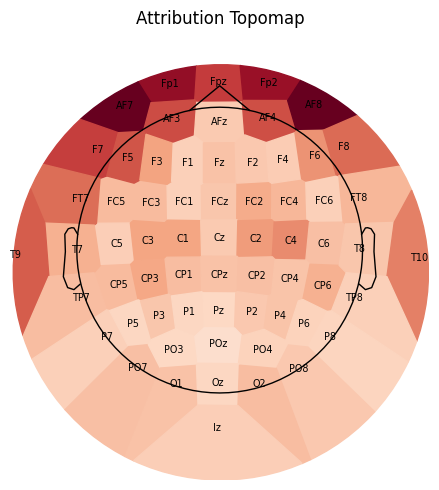

=== FDR Significant Electrodes Summary ===


,channel_idx,channel_name,mean_abs_relevance,std_abs_relevance,U,z,p,p_adj,r
21,21,Fp1,0.036419,0.020261,11138.0,3.801684,0.000072,0.000657,0.122699
22,22,Fpz,0.028863,0.018087,10127.0,2.852788,0.002167,0.013868,0.092073
23,23,Fp2,0.035520,0.017618,11611.0,4.245629,0.000011,0.000231,0.137027
24,24,AF7,0.041311,0.020386,12073.0,4.679249,0.000001,0.000071,0.151022
25,25,AF3,0.026847,0.008610,11427.0,4.072931,0.000023,0.000297,0.131453
27,27,AF4,0.026784,0.008996,11341.0,3.992214,0.000033,0.000349,0.128848
28,28,AF8,0.041221,0.019960,11979.0,4.591023,0.000002,0.000071,0.148175
29,29,F7,0.028403,0.011022,11543.0,4.181806,0.000014,0.000231,0.134967
30,30,F5,0.025895,0.012044,10771.0,3.457228,0.000273,0.002183,0.111582
37,37,F8,0.023455,0.009943,10429.0,3.136237,0.000856,0.006085,0.101222


In [7]:
mean_spatial_15 = mat_15runs_norm.mean(axis=0)

fig, ax = plt.subplots(figsize=(6, 5))
attribution_topomap(
    mean_spatial_15,
    channel_names=physio_ch_names,
    ax=ax
)
plt.tight_layout()
plt.show()

# Print detailed summary of FDR significant electrodes
sig_channels = sig_15_df[sig_15_df['sig_fdr']]
print("=== FDR Significant Electrodes Summary ===")
display(sig_channels[['channel_idx', 'channel_name', 'mean_abs_relevance', 'std_abs_relevance', 'U', 'z', 'p', 'p_adj', 'r']])

## 4. Spearman Rank Correlation: Electrode Relevances vs. Test Balanced Accuracy
To evaluate whether models with higher classification performance rely more heavily on specific scalp electrodes, we
compute the non-parametric **Spearman rank correlation** ($\rho$) between each electrode's relative spatial relevance
and the test set **balanced accuracy** across all 15 independent runs.

- **Statistical significance**: each electrode yields a correlation coefficient $\rho_c$ and a p-value under
  $H_0: \rho = 0$. We apply **Benjamini–Hochberg FDR control** ($p_\mathrm{FDR} < .05$) across the 64 electrodes.
- **Topomap**: $\rho_c$ is shown as a scalp topomap: positive values mark electrodes whose higher relevance goes with
  higher accuracy, negative values those whose higher relevance goes with lower accuracy.

Total Electrodes Tested: 64
Electrodes with Raw Spearman p < 0.05: 16 / 64
Electrodes with Benjamini-Hochberg FDR p_adj < 0.05: 2 / 64.
These Electrodes are: ['Fp2' 'FT7']


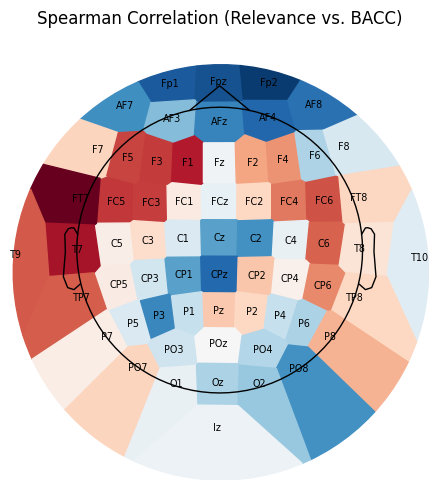

=== Top Positively Correlated Electrodes (Focus -> Higher Accuracy) ===


,channel_idx,channel_name,rho,p_value,p_adj,sig_raw,sig_fdr
38,38,FT7,0.825000,0.000153,0.009807,True,True
40,40,T7,0.685714,0.004772,0.061085,True,False
32,32,F1,0.653571,0.008230,0.069693,True,False
0,0,FC5,0.582143,0.022794,0.138744,True,False
31,31,F3,0.578571,0.023847,0.138744,True,False
1,1,FC3,0.567857,0.027228,0.145218,True,False
30,30,F5,0.560714,0.029676,0.146100,True,False
6,6,FC6,0.525000,0.044484,0.177936,True,False
42,42,T9,0.503571,0.055655,0.182240,False,False
44,44,TP7,0.496429,0.059797,0.182240,False,False



=== Top Negatively Correlated Electrodes (Focus -> Lower Accuracy) ===


,channel_idx,channel_name,rho,p_value,p_adj,sig_raw,sig_fdr
23,23,Fp2,-0.789286,0.000467,0.014954,True,True
22,22,Fpz,-0.721429,0.002399,0.051176,True,False
21,21,Fp1,-0.692857,0.004190,0.061085,True,False
27,27,AF4,-0.657143,0.007770,0.069693,True,False
17,17,CPz,-0.650000,0.008712,0.069693,True,False
28,28,AF8,-0.614286,0.014834,0.105486,True,False
26,26,AFz,-0.553571,0.032287,0.147598,True,False
48,48,P3,-0.535714,0.039567,0.168819,True,False
24,24,AF7,-0.507143,0.053664,0.182240,False,False
11,11,C2,-0.500000,0.057699,0.182240,False,False


In [8]:
from scipy.stats import spearmanr

# 1. Extract Test Balanced Accuracy across all 15 runs
bacc_list = []
for info in run_info:
    cfg = info['config']
    r_idx = info['run']
    perf_df = experiment_data[cfg]['results'].performance_df
    run_bacc = perf_df.loc[perf_df['run'] == r_idx, 'test_balanced_accuracy'].values[0]
    bacc_list.append(run_bacc)

bacc_vec = np.array(bacc_list) # Shape: (15,)

# 2. Normalize spatial relevance per run (L1-normalized relative relevance)
mat_15runs_norm = mat_15runs_ab / np.sum(mat_15runs_ab, axis=1, keepdims=True)

# 3. Compute Channel-Wise Spearman Correlation
corr_results = []
for c in range(64):
    rel_c = mat_15runs_norm[:, c]
    rho, pval = spearmanr(rel_c, bacc_vec)
    corr_results.append({
        'channel_idx': c,
        'channel_name': physio_ch_names[c],
        'rho': rho,
        'p_value': pval
    })

corr_df = pd.DataFrame(corr_results)
corr_df['p_adj'] = false_discovery_control(corr_df['p_value'].fillna(1.0).values)
corr_df['sig_raw'] = corr_df['p_value'] < alpha
corr_df['sig_fdr'] = corr_df['p_adj'] < alpha

print(f"Total Electrodes Tested: {len(corr_df)}")
print(f"Electrodes with Raw Spearman p < {alpha}: {corr_df['sig_raw'].sum()} / 64")
print(f"Electrodes with Benjamini-Hochberg FDR p_adj < {alpha}: {corr_df['sig_fdr'].sum()} / 64.")
print(f"These Electrodes are: {corr_df.loc[corr_df['sig_fdr']]['channel_name'].values}")

# 4. Plot Correlation Topomap
fig, ax = plt.subplots(figsize=(6, 5))
attribution_topomap(
    corr_df['rho'].values,
    channel_names=physio_ch_names,
    title="Spearman Correlation (Relevance vs. BACC)",
    ax=ax
)
plt.tight_layout()
plt.show()

# 5. Display Summary Tables
print("=== Top Positively Correlated Electrodes (Focus -> Higher Accuracy) ===")
display(corr_df.sort_values('rho', ascending=False).head(10)[['channel_idx', 'channel_name', 'rho', 'p_value', 'p_adj', 'sig_raw', 'sig_fdr']])

print("\n=== Top Negatively Correlated Electrodes (Focus -> Lower Accuracy) ===")
display(corr_df.sort_values('rho', ascending=True).head(10)[['channel_idx', 'channel_name', 'rho', 'p_value', 'p_adj', 'sig_raw', 'sig_fdr']])


In [9]:
# 📊  Beautiful Spearman‑Correlation Summary (Markdown)


# -------------------------------------------------
# 1️⃣  Load the correlation DataFrame that was already
#     created in the previous cell (`corr_df`).
# -------------------------------------------------
import pandas as pd
from IPython.display import Markdown, display

# ------------------------------------------------------------------
# 2️⃣  Keep only the FDR‑significant electrodes (α = 0.05) and sort
#     by the adjusted p‑value (smallest → most significant).
# ------------------------------------------------------------------
alpha = 0.05
sig_corr = (
    corr_df[corr_df["p_adj"] < alpha]  # keep FDR‑significant rows
    .sort_values("p_adj")  # order by corrected p‑value
    [["channel_name", "rho", "p_value", "p_adj"]]
    .rename(
        columns={
            "channel_name": "Channel",
            "rho": "Spearman ρ",
            "p_value": "Raw p‑value",
            "p_adj": "FDR‑adj. p",
        }
    )
)

# ------------------------------------------------------------------
# 3️⃣  Convert the DataFrame to a markdown table.
# ------------------------------------------------------------------
# `to_markdown` is available in pandas ≥1.0.0.
md_table = sig_corr.to_markdown(index=False)

# ------------------------------------------------------------------
# 4️⃣  Show the markdown in the notebook (nice, monospaced table).
# ------------------------------------------------------------------
display(Markdown("### 📈 FDR‑significant Spearman correlations\n" + md_table))

### 📈 FDR‑significant Spearman correlations
| Channel   |   Spearman ρ |   Raw p‑value |   FDR‑adj. p |
|:----------|-------------:|--------------:|-------------:|
| FT7       |     0.825    |   0.000153236 |   0.00980708 |
| Fp2       |    -0.789286 |   0.000467327 |   0.0149545  |

**Spearman correlations in APA format and as LaTeX table.** The values are those computed above, unchanged; only the
reporting is added: $r_s(\mathit{df})$ with $\mathit{df} = n - 2$, p, and FDR-adjusted p.
Two tables are written to `results/apa_mwu/`: FDR-significant electrodes (printed) and all electrodes (`longtable`).

In [10]:
n_runs = len(bacc_vec)
corr_df["apa"] = [f"r_s({n_runs - 2}) = {fmt_bounded(s['rho'])}, p {fmt_p(s['p_value'])}, p_FDR {fmt_p(s['p_adj'])}"
                  for s in corr_df.to_dict("records")]
for s in corr_df.loc[corr_df["sig_fdr"]].sort_values("p_value").to_dict("records"):
    print(f"  {s['channel_name']}: {s['apa']}")


def spearman_table(tab, which, long=False):
    rows = [[s["channel_name"], tex_num(s["rho"], bounded=True), tex_p(s["p_value"]), tex_p(s["p_adj"])]
            for s in tab.sort_values("p_value").to_dict("records")]
    caption = (f"PhysioMI L/R: {which}. Spearman rank correlation between the relative relevance of each electrode and "
               f"the test balanced accuracy across $n = {n_runs}$ runs ($\\mathit{{df}} = {n_runs - 2}$); "
               f"Benjamini--Hochberg FDR correction across {len(corr_df)} electrodes.")
    return booktabs(["Electrode", "$r_s$", "$p$", r"$p_{\mathrm{FDR}}$"], rows, "lrrr", caption,
                    f"tab:physiomi_spearman_bacc{'_all' if long else ''}", long=long)


tex_spearman_significant = spearman_table(corr_df.loc[corr_df["sig_fdr"]], "electrodes with FDR-significant correlation")
print(tex_spearman_significant)
write_output("physiomi_spearman_bacc_significant.tex", tex_spearman_significant)
write_output("physiomi_spearman_bacc_all.tex", spearman_table(corr_df, "all electrodes", long=True))

  FT7: r_s(13) = .82, p < .001, p_FDR = .010
  Fp2: r_s(13) = -.79, p < .001, p_FDR = .015
\begin{table}[ht]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{PhysioMI L/R: electrodes with FDR-significant correlation. Spearman rank correlation between the relative relevance of each electrode and the test balanced accuracy across $n = 15$ runs ($\mathit{df} = 13$); Benjamini--Hochberg FDR correction across 64 electrodes.}
\label{tab:physiomi_spearman_bacc}
\begin{tabular}{lrrr}
\toprule
Electrode & $r_s$ & $p$ & $p_{\mathrm{FDR}}$ \\
\midrule
FT7 & $.82$ & $< .001$ & $.010$ \\
Fp2 & $-.79$ & $< .001$ & $.015$ \\
\bottomrule
\end{tabular}
\end{table}
written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/physiomi_spearman_bacc_significant.tex
written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/physiomi_spearman_bacc_all.tex


## 4b. Output files: statistics cache

`results/apa_mwu/physiomi_stats.json` holds everything needed to check or redo the tests without the run data:
the inputs (channel names, runs, relative relevance matrix, test balanced accuracies), all test results,
the ranksums check, the test settings, the git commit and library versions, and the data folders that were read.
`results/apa_mwu/physiomi_electrode_mwu.csv` and `results/apa_mwu/physiomi_spearman_bacc.csv` hold the per-electrode
Mann–Whitney U and Spearman results as tables.

In [11]:
MWU_COLUMNS = ['channel_idx', 'channel_name', 'n_x', 'mdn_x', 'q1_x', 'q3_x', 'n_y', 'mdn_y', 'q1_y', 'q3_y', 'U', 'z', 'p', 'p_adj', 'r', 'A', 'n_tied_values', 'sig_raw', 'sig_fdr', 'sentence', 'sentence_short']
stats_cache = {
    "description": "PhysioMI left/right hand, frozen, from_scratch and finetuned LaBraM, 5 runs each",
    "provenance": provenance({label: os.path.realpath(path) for label, path in EXPERIMENT_MAP.items()}),
    "inputs": {
        "channel_names": list(physio_ch_names),
        "runs": run_info,
        "relative_relevance": mat_15runs_norm,  # rows: runs (order of "runs"), columns: channel_names
        "test_balanced_accuracy": bacc_vec,
    },
    "electrode_vs_background_mwu": {
        "alternative": "greater (electrode relevance tends to be larger than background relevance)",
        "alpha": alpha,
        "multiple_testing": "Benjamini-Hochberg FDR across electrodes",
        "background_description": background_description,
        "results": sig_15_df[MWU_COLUMNS],
    },
    "check_against_ranksums": ranksums_check,
    "spearman_relevance_vs_test_balanced_accuracy": {
        "alpha": alpha,
        "multiple_testing": "Benjamini-Hochberg FDR across electrodes",
        "results": corr_df[["channel_idx", "channel_name", "rho", "p_value", "p_adj", "sig_fdr", "apa"]],
    },
}
write_output("physiomi_stats.json", stats_cache)
sig_15_df[MWU_COLUMNS].to_csv(STATS_DIR / "physiomi_electrode_mwu.csv", index=False)
print(f"written: {STATS_DIR / 'physiomi_electrode_mwu.csv'}")
corr_df.to_csv(STATS_DIR / "physiomi_spearman_bacc.csv", index=False)
print(f"written: {STATS_DIR / 'physiomi_spearman_bacc.csv'}")

written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/physiomi_stats.json
written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/physiomi_electrode_mwu.csv
written: /viper/u1/$USER/projects/foundational_xai_in_neuroimaging/results/apa_mwu/physiomi_spearman_bacc.csv


## 5. Training Metrics & Overfitting Correlation Analysis
To investigate whether models overfit on spurious features or rely on specific electrodes during training, we extract
the epoch-level training balanced accuracy (`train_balanced_accuracy`) from the TensorBoard logs of all 15 independent
runs and compute:

1. **Train BACC correlation**: $\rho(\tilde{M}_c, \mathrm{BACC}_\mathrm{train})$, identifying which electrodes scale with training set performance.
2. **Generalization gap correlation**: $\rho(\tilde{M}_c, \Delta_\mathrm{BACC})$ with $\Delta_\mathrm{BACC} = \mathrm{BACC}_\mathrm{train} - \mathrm{BACC}_\mathrm{test}$, quantifying which electrode reliance goes with overfitting.

Total Electrodes Tested: 64
Electrodes with Overfitting Gap FDR p_adj < 0.05: 0 / 64


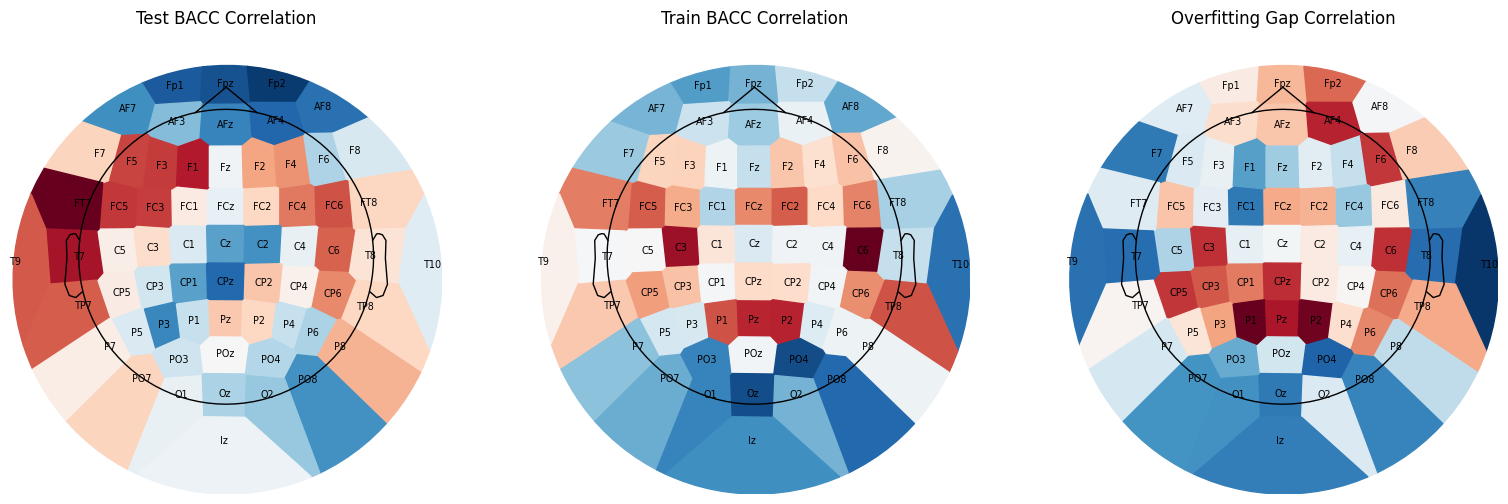

=== Top Electrodes Correlated with Overfitting Gap (Train BACC - Test BACC) ===


,channel_idx,channel_name,rho_gap,p_val_gap,p_adj_gap,rho_train,p_adj_train
49,49,P1,0.607143,0.016381,0.417733,0.460714,0.432472
51,51,P2,0.592857,0.019846,0.417733,0.560714,0.295196
50,50,Pz,0.496429,0.059797,0.417733,0.553571,0.295196
27,27,AF4,0.467857,0.078630,0.417733,-0.046429,0.975244
17,17,CPz,0.450000,0.092357,0.417733,0.139286,0.895460
13,13,C6,0.442857,0.098294,0.417733,0.725000,0.142530
8,8,C3,0.442857,0.098294,0.417733,0.621429,0.214432
14,14,CP5,0.432143,0.107693,0.417733,0.303571,0.667953
36,36,F6,0.428571,0.110960,0.417733,0.214286,0.848862
15,15,CP3,0.378571,0.164091,0.500086,0.210714,0.848862


In [12]:
import glob, os
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# 1. Extract final epoch Train Balanced Accuracy and Overfitting Gap across all 15 runs
train_bacc_list = []

for info in run_info:
    cfg = info['config']
    r_idx = info['run']
    run_folder = experiment_data[cfg]['results'].run_dirs[r_idx]
    
    tfevents = glob.glob(os.path.join(run_folder, 'events.out.tfevents.*.0'))
    if not tfevents:
        tfevents = glob.glob(os.path.join(run_folder, 'events.out.tfevents.*'))
    
    tr_val = np.nan
    for tf in tfevents:
        ea = EventAccumulator(tf)
        ea.Reload()
        tags = ea.Tags()['scalars']
        if 'train_balanced_accuracy' in tags:
            events = ea.Scalars('train_balanced_accuracy')
            tr_val = events[-1].value
    train_bacc_list.append(tr_val)

train_bacc_vec = np.array(train_bacc_list)
overfit_gap_vec = train_bacc_vec - bacc_vec

# 2. Compute Spearman Correlations for Train BACC & Overfitting Gap
corr_overfit = []
for c in range(64):
    rel_c = mat_15runs_norm[:, c]
    rho_tr, pval_tr = spearmanr(rel_c, train_bacc_vec)
    rho_gap, pval_gap = spearmanr(rel_c, overfit_gap_vec)
    corr_overfit.append({
        'channel_idx': c,
        'channel_name': physio_ch_names[c],
        'rho_train': rho_tr,
        'p_val_train': pval_tr,
        'rho_gap': rho_gap,
        'p_val_gap': pval_gap
    })

overfit_df = pd.DataFrame(corr_overfit)
overfit_df['p_adj_train'] = false_discovery_control(overfit_df['p_val_train'].fillna(1.0).values)
overfit_df['p_adj_gap'] = false_discovery_control(overfit_df['p_val_gap'].fillna(1.0).values)
overfit_df['sig_fdr_gap'] = overfit_df['p_adj_gap'] < alpha

print(f"Total Electrodes Tested: {len(overfit_df)}")
print(f"Electrodes with Overfitting Gap FDR p_adj < {alpha}: {overfit_df['sig_fdr_gap'].sum()} / 64")

# 3. Plot Side-by-Side Topomaps: Test BACC vs Train BACC vs Overfitting Gap
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

attribution_topomap(
    corr_df['rho'].values,
    channel_names=physio_ch_names,
    title="Test BACC Correlation",
    ax=axes[0]
)

attribution_topomap(
    overfit_df['rho_train'].values,
    channel_names=physio_ch_names,
    title="Train BACC Correlation",
    ax=axes[1]
)

attribution_topomap(
    overfit_df['rho_gap'].values,
    channel_names=physio_ch_names,
    title="Overfitting Gap Correlation",
    ax=axes[2]
)

plt.tight_layout()
plt.show()

# 4. Print Summary Tables
print("=== Top Electrodes Correlated with Overfitting Gap (Train BACC - Test BACC) ===")
display(overfit_df.sort_values('rho_gap', ascending=False).head(10)[['channel_idx', 'channel_name', 'rho_gap', 'p_val_gap', 'p_adj_gap', 'rho_train', 'p_adj_train']])
